# Options Flow, Delta y Gamma

Cada figura se crea en la celda visible que sigue a sus parámetros. Edita el bloque de configuración y ejecuta **todas** las celdas para regenerarlas. Las tablas completas se consultan en la terminal o en los CSV de la ejecución. Los datos de capturas no identifican compras/ventas individuales.

In [1]:
# 1. CAMBIA ESTOS PARÁMETROS Y VUELVE A EJECUTAR LAS CELDAS
RUTA_INFORME = 'ejemplos/informe_sintetico.json'  # Relativa a la raíz del proyecto o ruta absoluta.

# Filtros de contenido: cambian qué datos se dibujan, no los cálculos guardados.
FILTROS = {
    "vencimientos": [],         # [] = todos; ejemplo: ["2026-11-17"]
    "tipos": ["CALL", "PUT"], # quita un tipo para ocultarlo
    "strike_min": None,
    "strike_max": None,
    "distancia_spot_pct": 0.12, # None para mostrar todos
    "max_strikes": 40,         # None para mostrar todos
}

# Apariencia: todos los colores y tamaños están aquí y puedes cambiar el código de cada figura.
ESTILO = {
    "tema": "default",       # "dark_background" para tema oscuro
    "colores": {"CALL": "#167dba", "PUT": "#e58a35", "positivo": "#148a73",
                "negativo": "#c74b59", "spot": "#7e57c2", "volumen": "#8898a5"},
    "figsize": (12, 5),
    "dpi": 150,
    "fuente": "DejaVu Sans",
    "tamano_fuente": 10,
    "ancho_barra": None,     # None = automático según distancia entre strikes
    "grosor_linea": 1.2,
    "opacidad": 0.85,
    "escala_y": "linear",  # también "symlog"
    "divisor_unidades": 1000, # 1, 1000 o 1_000_000, por ejemplo
    "prefijo_titulo": "",
    "titulos": {},        # ejemplo: {"delta_strike": "Mi título | {titulo}"}
    "etiquetas_x": {},    # ejemplo: {"delta_strike": "Strike (USD)"}
    "limites_y": {},      # ejemplo: {"delta_strike": (-100, 100)}
    "etiquetas": {"delta_strike": "Delta × OI × M ({unidad})",
                 "gamma_strike": "Gamma × OI × M ({unidad} por punto)",
                 "delta_vencimiento": "Delta × OI × M ({unidad})",
                 "gamma_vencimiento": "Gamma × OI × M ({unidad} por punto)",
                 "volumen_actual": "Volumen acumulado informado (contratos)",
                 "volumen_incremental": "Incremento estimado comparable (contratos)",
                 "gamma_dealer": "Gamma hipotética × OI × M ({unidad} por punto)"},
}

SERIES = {
    "delta_strike": True, "gamma_strike": True, "por_vencimiento": True,
    "actividad": True, "escenario_dealer": True,
    "mostrar_spot": True, "linea_cero": True, "cuadricula": True,
    "leyenda": True, "anotaciones": False, "max_anotaciones": 8,
}

EXPORTACION = {
    "activar": False,
    "carpeta": 'resultados/graficas_demo',
    "formatos": ["png"],  # también "svg" o "pdf"
    "fondo_transparente": False,
    "sobrescribir": False,
}


In [2]:
from pathlib import Path
import hashlib, json, re
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLAN_REDISENO.md").exists()), None)
if RAIZ is None:
    raise FileNotFoundError("Abre el notebook dentro del proyecto kronos")
RUTA = Path(RUTA_INFORME)
if not RUTA.is_absolute():
    RUTA = RAIZ / RUTA
RUTA = RUTA.resolve()
contenido = RUTA.read_bytes()
informe = json.loads(contenido)
huella_informe = hashlib.sha256(contenido).hexdigest()
meta = informe["captura_actual"]["metadatos"]
spot = float(meta["spot"])
simbolo = meta["subyacente"]
plt.style.use(ESTILO["tema"])
plt.rcParams.update({"font.family": ESTILO["fuente"], "font.size": ESTILO["tamano_fuente"]})
display(Markdown(
    f"**Fuente:** `{RUTA}`  \n**Activo:** {simbolo}  \n"
    f"**Captura UTC:** {meta['capturado_en_utc']}  \n**Proveedor:** {meta['proveedor']}  \n"
    f"**SHA-256 del informe:** `{huella_informe}`  \n"
    "Las figuras ponderadas por OI son hipótesis de contratos largos; la actividad proviene de capturas, no de operaciones."
))


**Fuente:** `D:\02_Herramientas\kronos\ejemplos\informe_sintetico.json`  
**Activo:** QQQ  
**Captura UTC:** 2026-11-16T15:05:00+00:00  
**Proveedor:** EJEMPLO_SINTETICO  
**SHA-256 del informe:** `ba7b1a3ffe9371b2fcc6c4e1a8bfc33c4e4ea1ed1b3c902770b1c1ecd97108fe`  
Las figuras ponderadas por OI son hipótesis de contratos largos; la actividad proviene de capturas, no de operaciones.

In [3]:
def tabla_filtrada(registros, *, con_tipo=True):
    tabla = pd.DataFrame(registros)
    if tabla.empty:
        return tabla
    tabla["strike"] = pd.to_numeric(tabla["strike"], errors="coerce")
    tabla = tabla.dropna(subset=["strike"])
    if FILTROS["vencimientos"]:
        tabla = tabla[tabla["vencimiento"].isin(FILTROS["vencimientos"])]
    if con_tipo and FILTROS["tipos"]:
        tabla = tabla[tabla["tipo"].isin(FILTROS["tipos"])]
    if FILTROS["strike_min"] is not None:
        tabla = tabla[tabla["strike"] >= FILTROS["strike_min"]]
    if FILTROS["strike_max"] is not None:
        tabla = tabla[tabla["strike"] <= FILTROS["strike_max"]]
    if FILTROS["distancia_spot_pct"] is not None:
        distancia = spot * FILTROS["distancia_spot_pct"]
        tabla = tabla[tabla["strike"].between(spot - distancia, spot + distancia)]
    maximo = FILTROS["max_strikes"]
    if maximo and tabla["strike"].nunique() > maximo:
        elegidos = sorted(tabla["strike"].unique(), key=lambda x: abs(x - spot))[:maximo]
        tabla = tabla[tabla["strike"].isin(elegidos)]
    return tabla.sort_values(["vencimiento", "strike"])

def ancho_barras(tabla):
    if ESTILO["ancho_barra"] is not None:
        return ESTILO["ancho_barra"]
    valores = sorted(tabla["strike"].unique())
    saltos = [b - a for a, b in zip(valores, valores[1:]) if b > a]
    return min(saltos) * 0.36 if saltos else 2.0

def decorar(ax, clave, titulo, *, spot_visible=True):
    titulo_final = ESTILO["titulos"].get(clave, "{titulo}").format(titulo=titulo)
    ax.set_title(ESTILO["prefijo_titulo"] + titulo_final)
    eje_x = "Strike" if "vencimiento" not in clave else "Vencimiento"
    ax.set_xlabel(ESTILO["etiquetas_x"].get(clave, eje_x))
    unidad = {1: "unidades", 1000: "miles de unidades", 1000000: "millones de unidades"}.get(
        ESTILO["divisor_unidades"], f"unidades / {ESTILO['divisor_unidades']}"
    )
    ax.set_ylabel(ESTILO["etiquetas"][clave].format(unidad=unidad))
    ax.set_yscale(ESTILO["escala_y"])
    if SERIES["linea_cero"]:
        ax.axhline(0, color=ESTILO["colores"]["volumen"], lw=ESTILO["grosor_linea"], alpha=0.6)
    if spot_visible and SERIES["mostrar_spot"]:
        ax.axvline(spot, color=ESTILO["colores"]["spot"], lw=ESTILO["grosor_linea"], ls="--", label="Spot")
    if SERIES["cuadricula"]:
        ax.grid(True, axis="y", alpha=0.25)
    if clave in ESTILO["limites_y"]:
        ax.set_ylim(*ESTILO["limites_y"][clave])
    if SERIES["leyenda"]:
        ax.legend()

def anotar(ax, barras):
    if not SERIES["anotaciones"]:
        return
    for barra in list(barras)[:SERIES["max_anotaciones"]]:
        y = barra.get_height()
        ax.annotate(f"{y:.1f}", (barra.get_x() + barra.get_width()/2, y),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)

def mostrar_y_exportar(fig, nombre):
    fig.tight_layout()
    if EXPORTACION["activar"]:
        carpeta = Path(EXPORTACION["carpeta"])
        if not carpeta.is_absolute():
            carpeta = RAIZ / carpeta
        carpeta.mkdir(parents=True, exist_ok=True)
        configuracion = json.dumps([FILTROS, ESTILO, SERIES, EXPORTACION], sort_keys=True, default=str)
        clave = hashlib.sha256((huella_informe + configuracion).encode()).hexdigest()[:10]
        for formato in EXPORTACION["formatos"]:
            nombre_seguro = re.sub(r"[^A-Za-z0-9_-]", "_", nombre)
            destino = carpeta / f"{simbolo}_{nombre_seguro}_{clave}.{formato}"
            if destino.exists() and not EXPORTACION["sobrescribir"]:
                print(f"Imagen existente: {destino}")
            else:
                fig.savefig(destino, dpi=ESTILO["dpi"], transparent=EXPORTACION["fondo_transparente"])
                print(f"Imagen exportada: {destino}")
    display(fig)  # La imagen queda dentro de la salida de esta celda Jupyter.
    plt.close(fig)

def figura_strike(campo, clave, titulo):
    tabla = tabla_filtrada(informe["agregados_strike"])
    if tabla.empty:
        print(f"Sin datos para {titulo} con estos filtros")
        return
    for vencimiento, grupo in tabla.groupby("vencimiento", sort=True):
        fig, ax = plt.subplots(figsize=ESTILO["figsize"], dpi=ESTILO["dpi"])
        ancho = ancho_barras(grupo)
        for tipo in FILTROS["tipos"]:
            lado = grupo[grupo["tipo"] == tipo].copy()
            lado[campo] = pd.to_numeric(lado[campo], errors="coerce")
            lado = lado.dropna(subset=[campo])
            if lado.empty:
                continue
            desplazamiento = -ancho/2 if tipo == "CALL" else ancho/2
            barras = ax.bar(lado["strike"] + desplazamiento,
                            lado[campo] / ESTILO["divisor_unidades"], width=ancho,
                            color=ESTILO["colores"][tipo], alpha=ESTILO["opacidad"], label=tipo)
            anotar(ax, barras)
        decorar(ax, clave, f"{titulo} | {vencimiento}")
        mostrar_y_exportar(fig, f"{clave}_{vencimiento}")


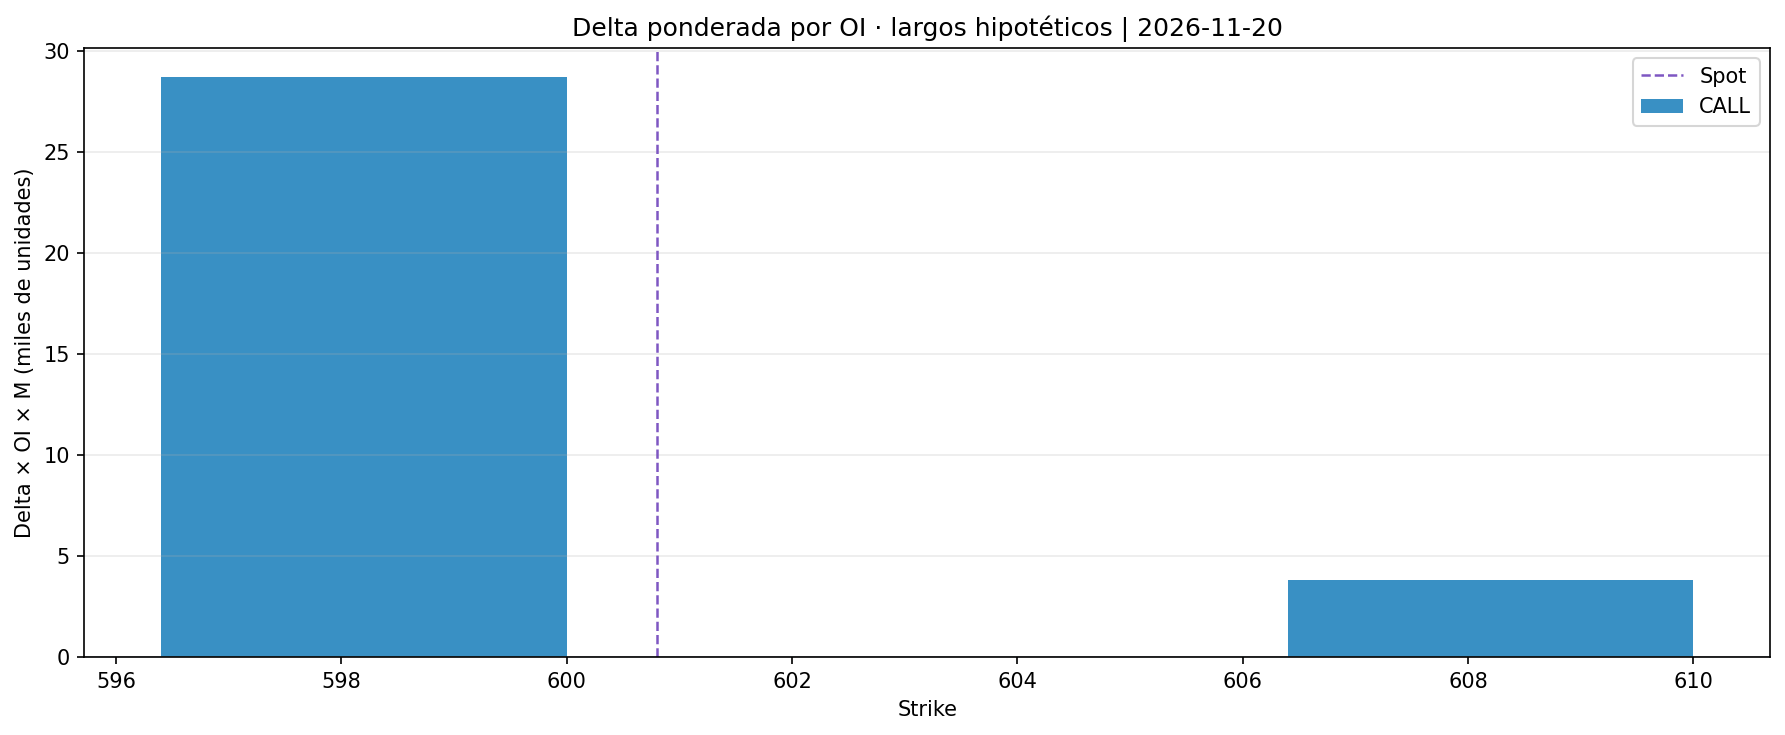

In [4]:
# 2. Delta por strike. Cambia FILTROS, ESTILO o el código y ejecuta de nuevo.
if SERIES["delta_strike"]:
    figura_strike("delta_oi_unidades", "delta_strike", "Delta ponderada por OI · largos hipotéticos")


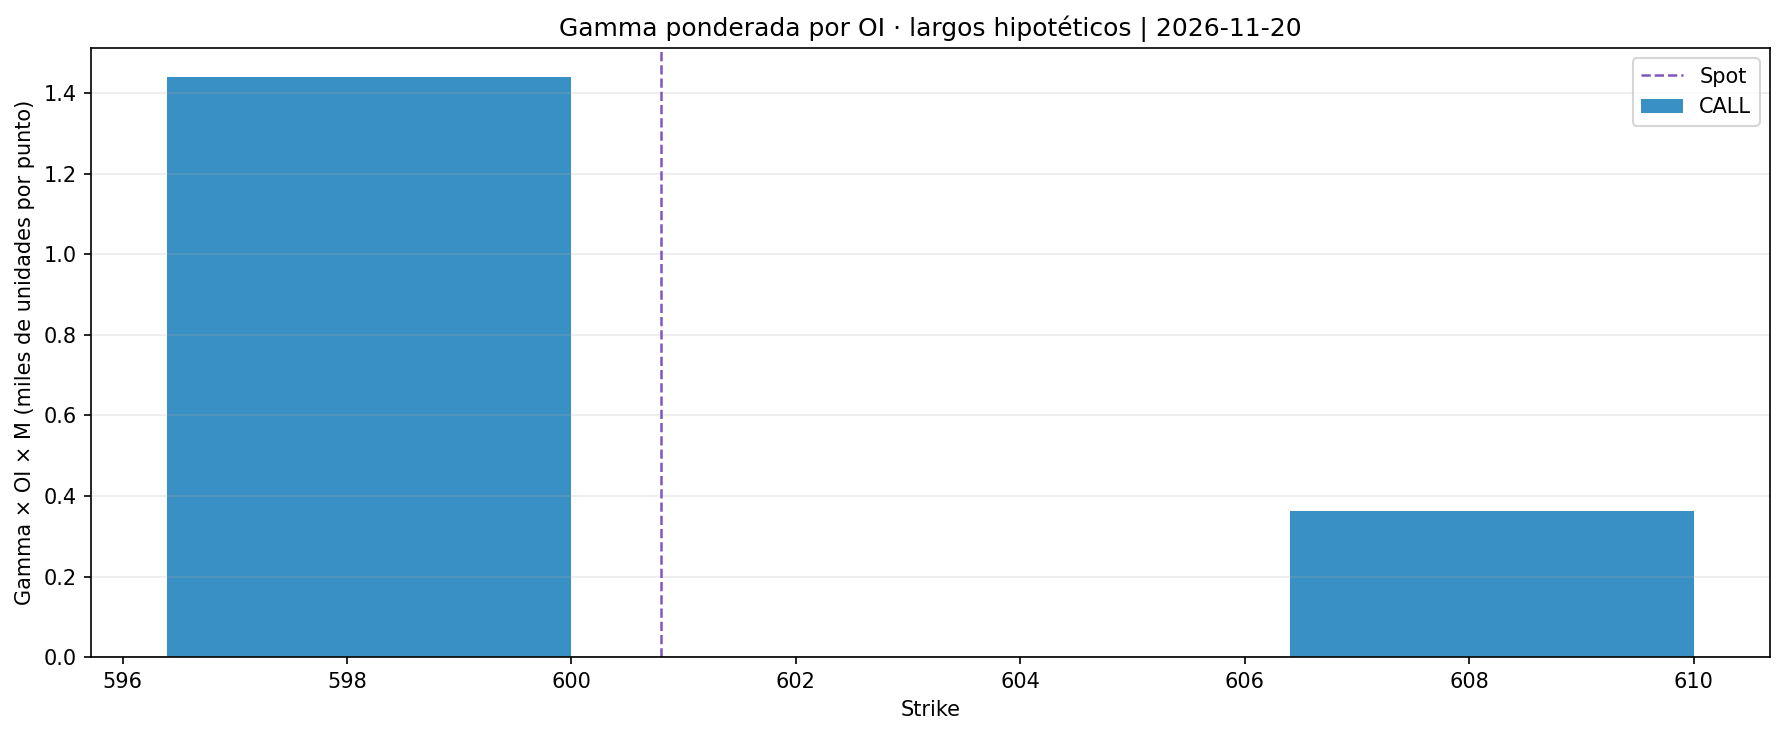

In [5]:
# 3. Gamma por strike. La escala y los colores son editables arriba.
if SERIES["gamma_strike"]:
    figura_strike("gamma_oi_unidades_por_precio", "gamma_strike", "Gamma ponderada por OI · largos hipotéticos")


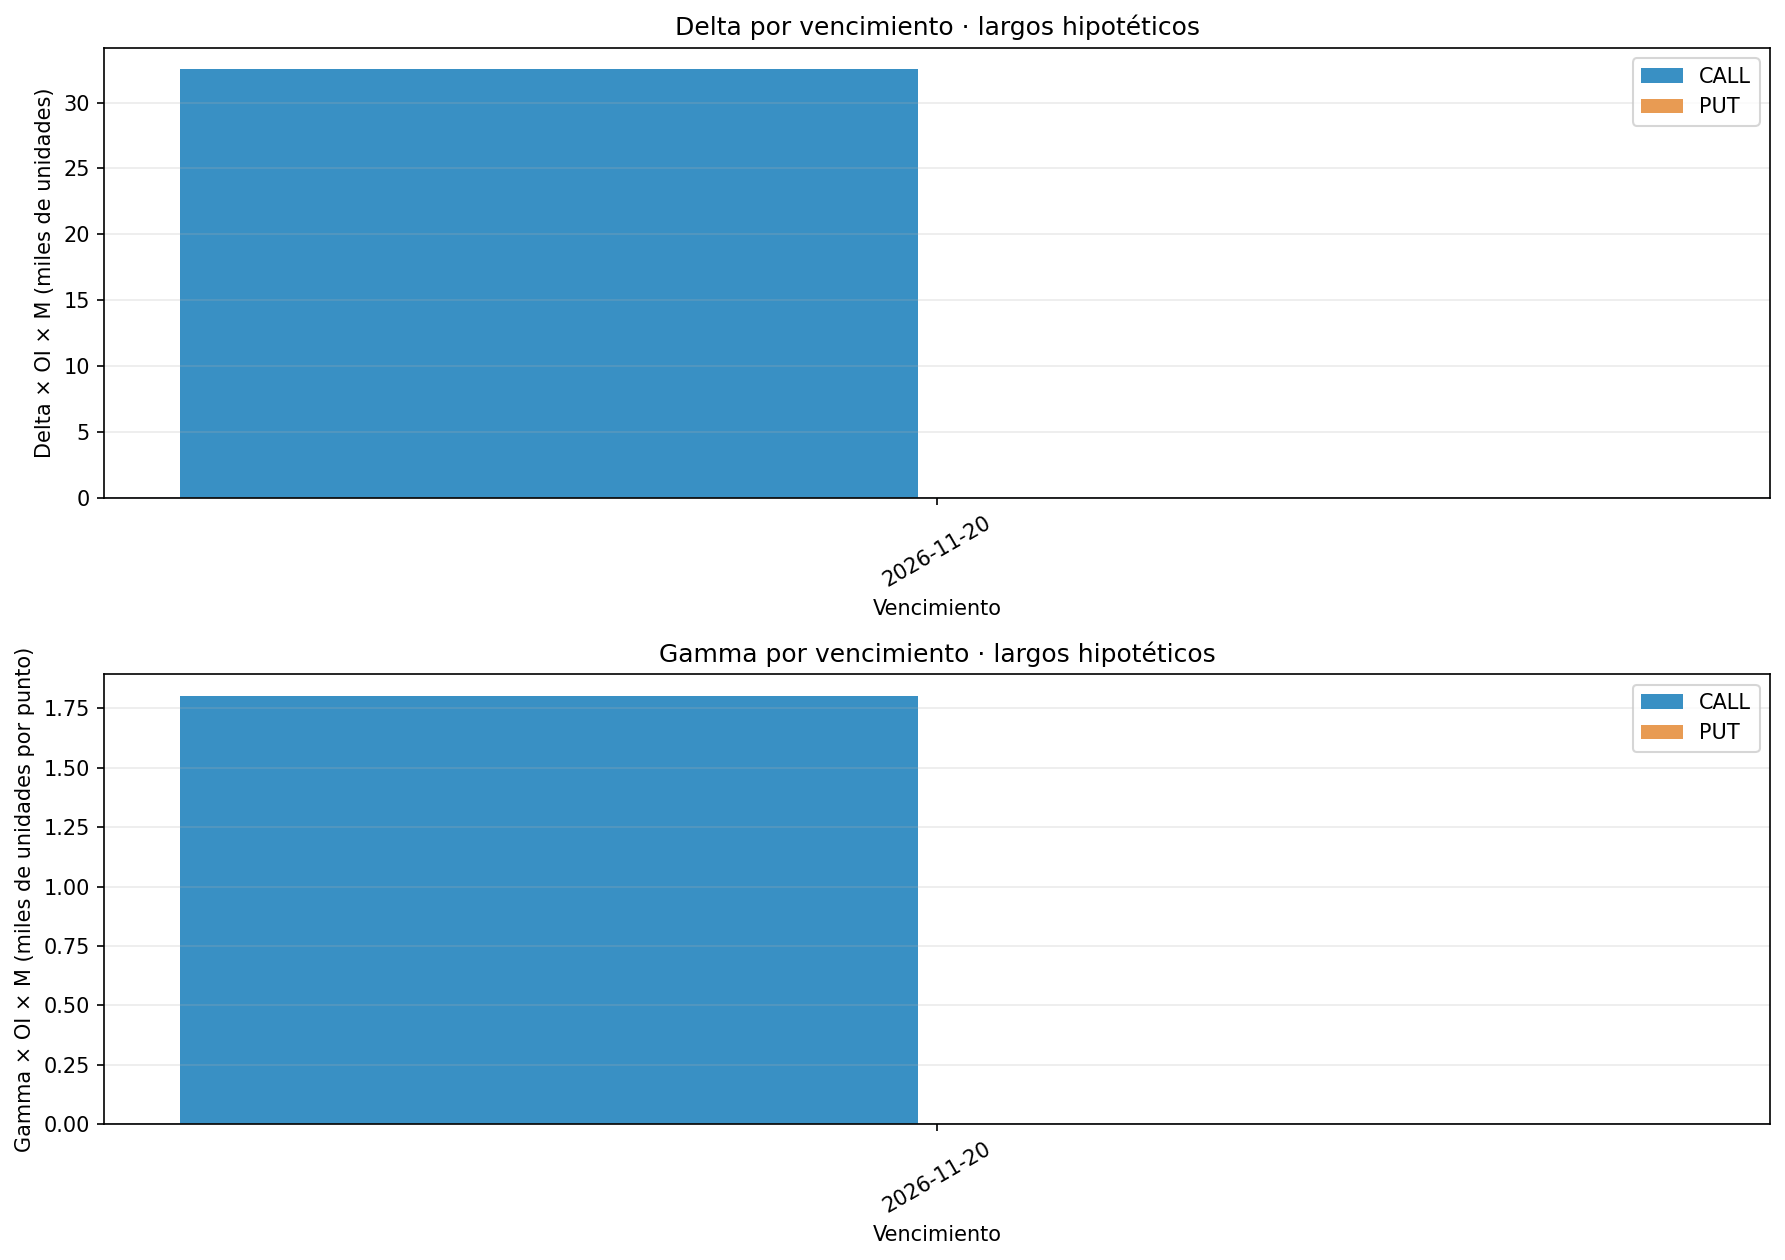

In [6]:
# 4. Delta y Gamma por vencimiento, calls y puts separados.
if SERIES["por_vencimiento"]:
    # Reagregar desde los strikes filtrados: así strike_min/max y distancia_spot
    # afectan también a esta vista, sin cambiar el informe original.
    detalle = tabla_filtrada(informe["agregados_strike"])
    if detalle.empty:
        datos = pd.DataFrame()
    else:
        columnas = ["delta_oi_unidades", "gamma_oi_unidades_por_precio"]
        for columna in columnas:
            detalle[columna] = pd.to_numeric(detalle[columna], errors="coerce")
        datos = detalle.groupby(["vencimiento", "tipo"], as_index=False)[columnas].sum(min_count=1)
    if not datos.empty:
        fechas = sorted(datos["vencimiento"].unique())
        fig, ejes = plt.subplots(2, 1, figsize=(ESTILO["figsize"][0], ESTILO["figsize"][1]*1.7), dpi=ESTILO["dpi"])
        for ax, campo, clave, titulo in [
            (ejes[0], "delta_oi_unidades", "delta_vencimiento", "Delta por vencimiento"),
            (ejes[1], "gamma_oi_unidades_por_precio", "gamma_vencimiento", "Gamma por vencimiento")]:
            for tipo in FILTROS["tipos"]:
                lado = datos[datos["tipo"] == tipo].set_index("vencimiento")
                x = [i + (-0.2 if tipo == "CALL" else 0.2) for i in range(len(fechas))]
                y = [float(lado.loc[f, campo])/ESTILO["divisor_unidades"] if f in lado.index and pd.notna(lado.loc[f, campo]) else 0 for f in fechas]
                barras = ax.bar(x, y, width=0.38, color=ESTILO["colores"][tipo], alpha=ESTILO["opacidad"], label=tipo)
                anotar(ax, barras)
            ax.set_xticks(range(len(fechas)), fechas, rotation=30)
            decorar(ax, clave, titulo + " · largos hipotéticos", spot_visible=False)
        mostrar_y_exportar(fig, "delta_gamma_vencimiento")
    else:
        print("Sin agregados por vencimiento con estos filtros")


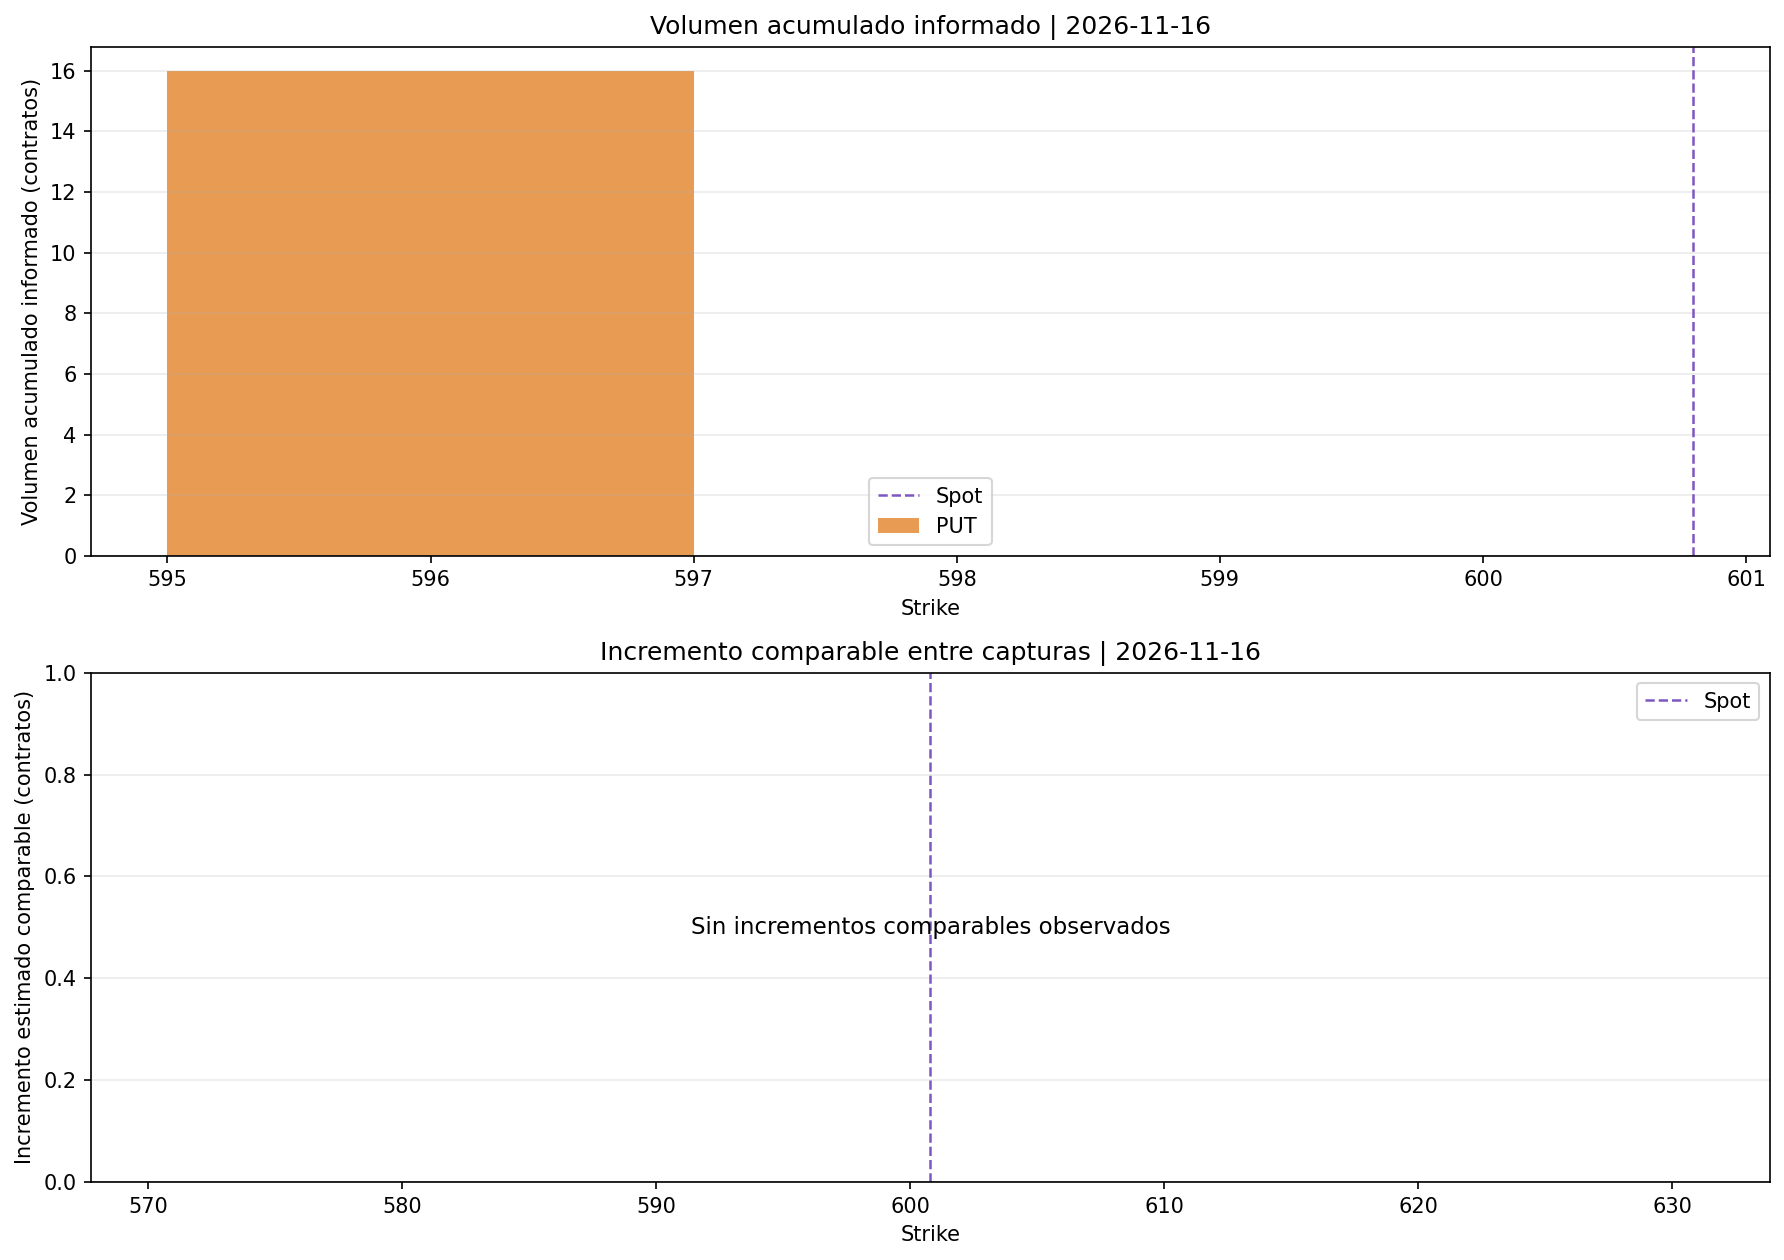

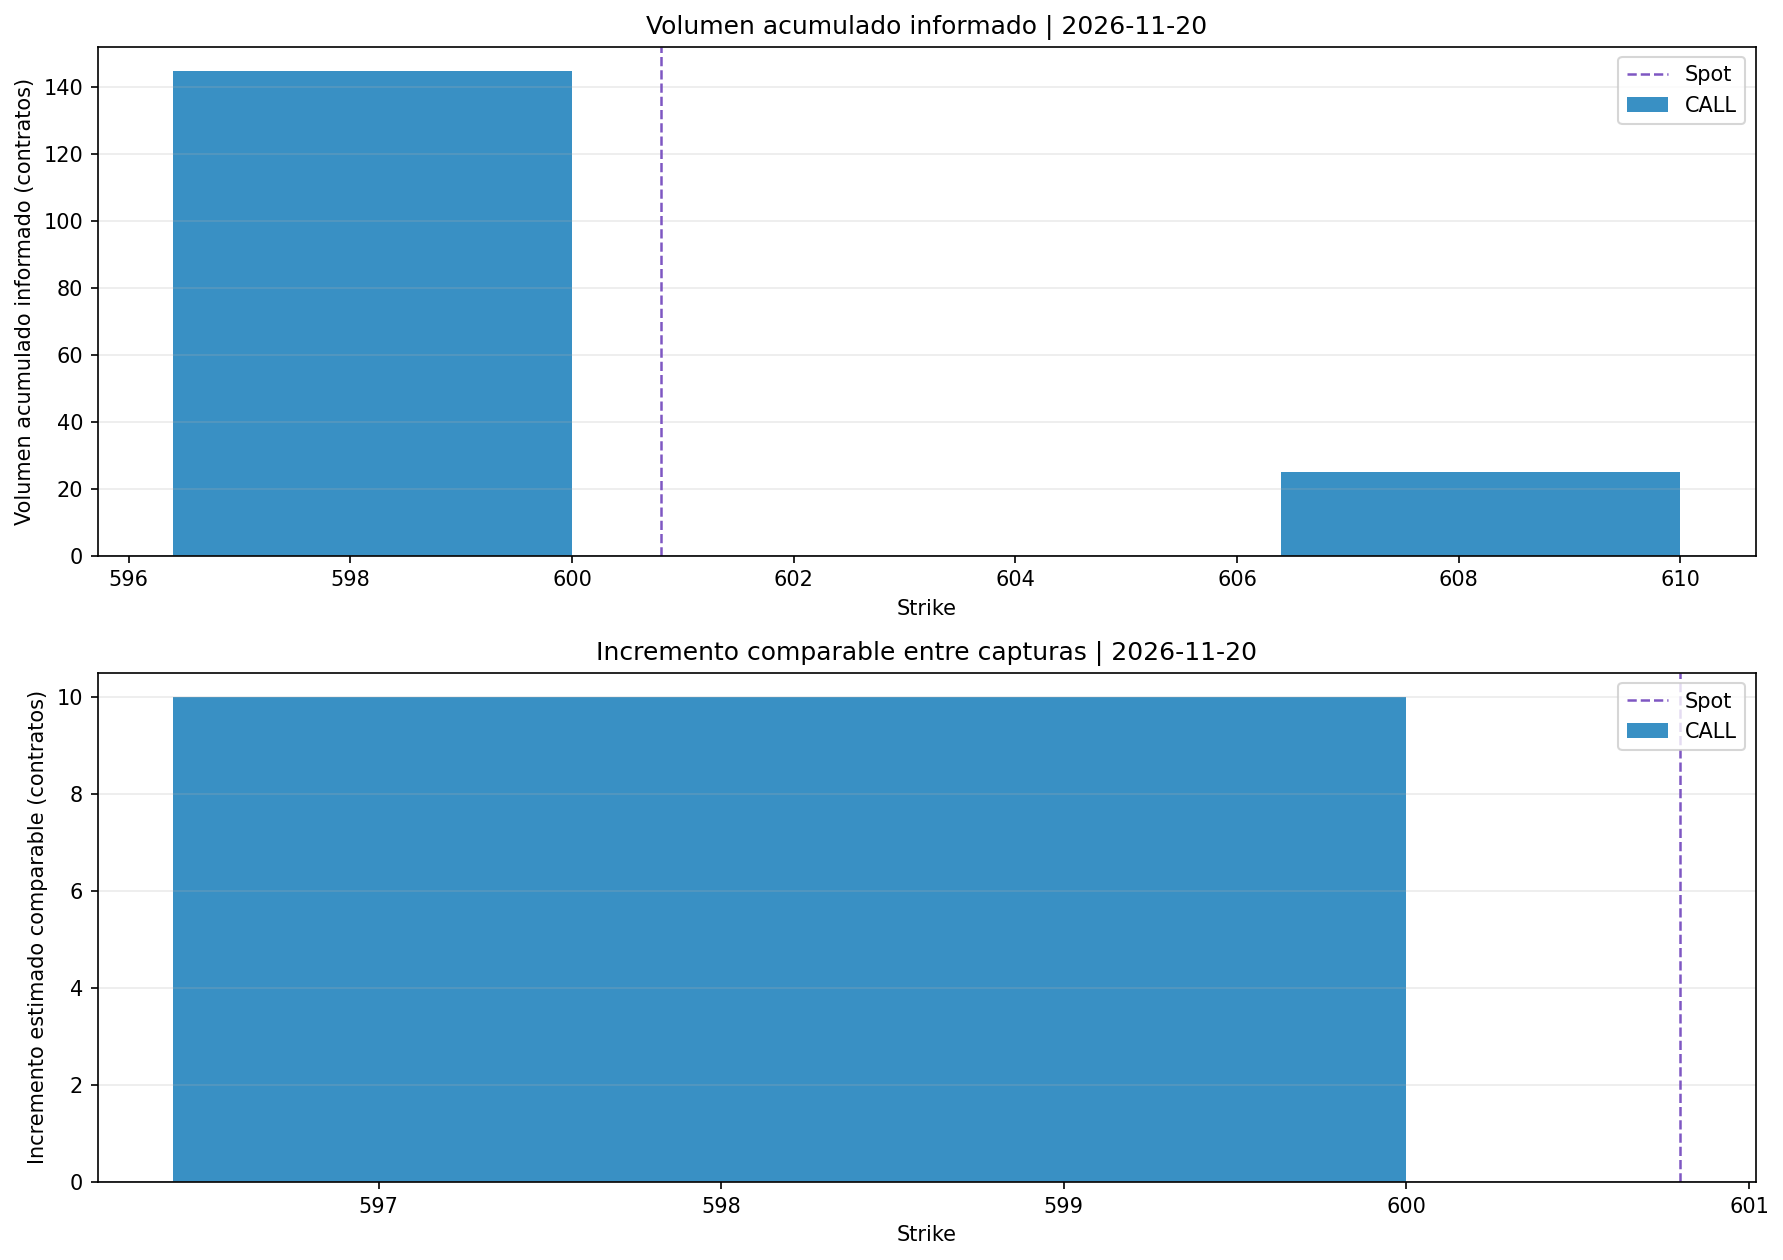

In [7]:
# 5. Options Flow: volumen informado y cambio estimado entre capturas, sin dirección de órdenes.
if SERIES["actividad"]:
    comparacion = informe.get("actividad")
    if comparacion is None:
        print("Esta ejecución no compara dos capturas; no hay figura de actividad")
    else:
        datos = tabla_filtrada(comparacion["contratos"])
        if datos.empty:
            print("Sin actividad visible con estos filtros")
        else:
            for vencimiento, grupo in datos.groupby("vencimiento", sort=True):
                fig, ejes = plt.subplots(2, 1, figsize=(ESTILO["figsize"][0], ESTILO["figsize"][1]*1.7), dpi=ESTILO["dpi"])
                ancho = ancho_barras(grupo)
                for ax, campo, clave, titulo in [
                    (ejes[0], "volumen_actual", "volumen_actual", "Volumen acumulado informado"),
                    (ejes[1], "incremento_volumen_estimado", "volumen_incremental", "Incremento comparable entre capturas")]:
                    for tipo in FILTROS["tipos"]:
                        lado = grupo[grupo["tipo"] == tipo].copy()
                        lado[campo] = pd.to_numeric(lado[campo], errors="coerce")
                        lado = lado.dropna(subset=[campo])
                        if lado.empty:
                            continue
                        desplazamiento = -ancho/2 if tipo == "CALL" else ancho/2
                        barras = ax.bar(lado["strike"] + desplazamiento, lado[campo], width=ancho,
                                        color=ESTILO["colores"][tipo], alpha=ESTILO["opacidad"], label=tipo)
                        anotar(ax, barras)
                    decorar(ax, clave, titulo + " | " + vencimiento, spot_visible=True)
                if pd.to_numeric(grupo["incremento_volumen_estimado"], errors="coerce").fillna(0).sum() == 0:
                    ejes[1].text(0.5, 0.5, "Sin incrementos comparables observados", transform=ejes[1].transAxes,
                                 ha="center", va="center", fontsize=ESTILO["tamano_fuente"] + 1)
                mostrar_y_exportar(fig, f"actividad_{vencimiento}")


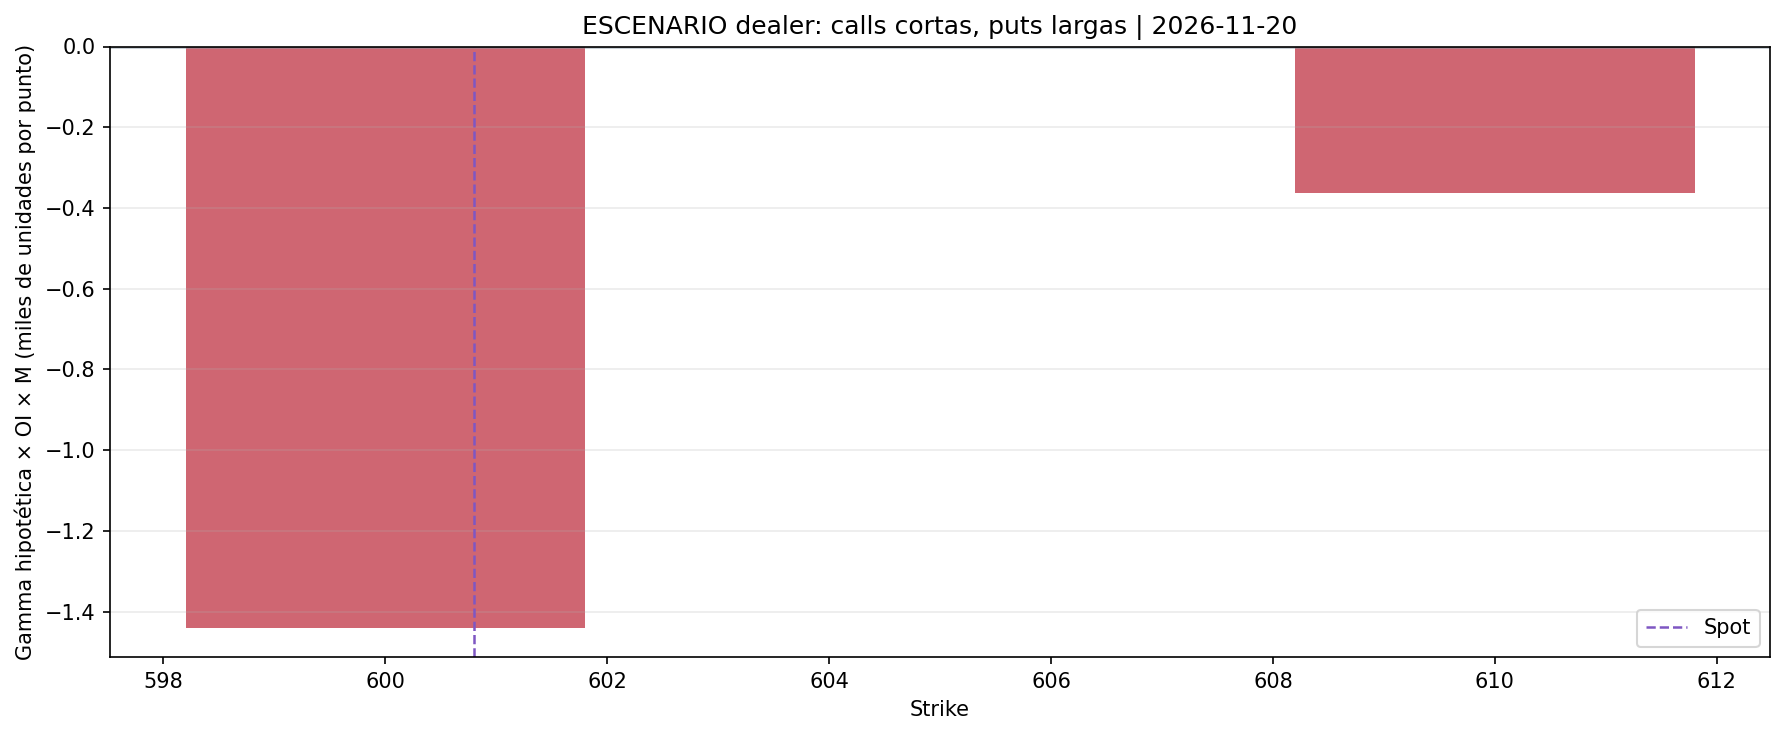

In [8]:
# 6. Escenario dealer opcional. El signo proviene de una hipótesis, no de posiciones observadas.
if SERIES["escenario_dealer"]:
    registros = informe.get("escenario_dealer_strike")
    if registros is None:
        print("Esta ejecución no incluyó --escenario-dealer")
    else:
        datos = tabla_filtrada(registros, con_tipo=False)
        for vencimiento, grupo in datos.groupby("vencimiento", sort=True):
            grupo = grupo.copy()
            grupo["gamma_oi_unidades_por_precio"] = pd.to_numeric(grupo["gamma_oi_unidades_por_precio"], errors="coerce")
            grupo = grupo.dropna(subset=["gamma_oi_unidades_por_precio"])
            if grupo.empty:
                continue
            valores = grupo["gamma_oi_unidades_por_precio"] / ESTILO["divisor_unidades"]
            colores = [ESTILO["colores"]["positivo"] if y >= 0 else ESTILO["colores"]["negativo"] for y in valores]
            fig, ax = plt.subplots(figsize=ESTILO["figsize"], dpi=ESTILO["dpi"])
            barras = ax.bar(grupo["strike"], valores, width=ancho_barras(grupo), color=colores, alpha=ESTILO["opacidad"])
            anotar(ax, barras)
            decorar(ax, "gamma_dealer", "ESCENARIO dealer: calls cortas, puts largas | " + vencimiento)
            mostrar_y_exportar(fig, f"gamma_dealer_{vencimiento}")
